Name: Christian Aron Vea

GitHub: https://github.com/ChristianAronVea/IND320-Vea

Streamlit: https://ind320-vea-5sc8vxsjg7v4bjgnpamvfl.streamlit.app/

Recording: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=7db6303f-2cb5-4f02-8134-b4fe010274d6


AI usage and log can be found in separate files in the repo.

In [70]:
import requests
import pandas as pd
from river import time_series, linear_model, preprocessing, optim, metrics
import calendar, math, itertools
import matplotlib.pyplot as plt

### Checking Norweigan bank API

In [32]:
# API for euro and usd from nowegian bank
url_bank = ("https://data.norges-bank.no/api/data/EXR/B.USD+EUR.NOK.SP?endPeriod=2026-11-26&format=sdmx-json&locale=no&startPeriod=2025-11-26")

r = requests.get(url_bank, timeout=10)
print(r.status_code)        # 200 is ok

data_bank = r.json()
print(data_bank.keys())

df_bank = pd.DataFrame(data_bank)
df_bank

200
dict_keys(['meta', 'data'])


,meta,data
id,IREF073301,NaN
prepared,2026-11-26T15:35:39,NaN
test,False,NaN
datasetId,f3d1cd78-3527-4ce3-a9a2-2e387e3e5bce,NaN
sender,{'id': 'Unknown'},NaN
receiver,{'id': 'guest'},NaN
links,"[{'rel': 'self', 'href': '/data/EXR/B.USD+EUR....",NaN
dataSets,NaN,"[{'links': [{'rel': 'dataflow', 'urn': 'urn:sd..."
structure,NaN,"{'links': [{'rel': 'dataflow', 'urn': 'urn:sdm..."


In [ ]:
# Getting the currency rates fron NB
def get_nb_rates(start, end, currencies=("USD", "EUR")):
    """    Start and end has format:  yyyy-mm-dd """
    
    url = (f"https://data.norges-bank.no/api/data/EXR/B.{'+'.join(currencies)}.NOK.SP"
           f"?startPeriod={start}&endPeriod={end}&format=sdmx-json")
    j = requests.get(url, timeout=30).json()["data"]
    dates = [v["id"] for v in j["structure"]["dimensions"]["observation"][0]["values"]]
    base_dim = [d for d in j["structure"]["dimensions"]["series"] if d["id"] == "BASE_CUR"][0]
    rows = []
    for key, s in j["dataSets"][0]["series"].items():
        cur = base_dim["values"][int(key.split(":")[1])]["id"]
        for i, obs in s["observations"].items():
            rows.append((dates[int(i)], cur, float(obs[0])))
    df = pd.DataFrame(rows, columns=["date", "currency", "rate"])
    df["date"] = pd.to_datetime(df["date"])
    return df

In [47]:
# Testing function to retrive NB data
bank_data = get_nb_rates("2026-02-01", "2026-02-04")
bank_data

,date,currency,rate
0,2026-02-02,USD,9.6837
1,2026-02-03,USD,9.6788
2,2026-02-04,USD,9.6442
3,2026-02-02,EUR,11.4655
4,2026-02-03,EUR,11.4220
5,2026-02-04,EUR,11.3995


In [34]:
# Timezones
"""
From searching through previous assignments, I can find that all APIs use the same time zones - local or Europe/Oslo.
"""

'\nFrom searching through previous assignments, I can find that all APIs use the same time zones - local or Europe/Oslo.\n'

### Making River Framework on SARIMAX

In [ ]:
magasinstatistikk = requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData")

df_mag = pd.DataFrame(magasinstatistikk.json())
df_mag = df_mag.sort_values(by="dato_Id")
df_mag = df_mag[(df_mag["omrType"] == "EL") & (df_mag["omrnr"] == 4)]  # NO4
df_mag

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
8285,1995-01-08,EL,4,1995,1,0.542160,21.079208,11.428300,0001-01-01T00:00:00,0.686501,-0.144341
8272,1995-01-15,EL,4,1995,2,0.525037,21.079208,11.067362,0001-01-01T00:00:00,0.542160,-0.017123
8232,1995-01-22,EL,4,1995,3,0.506964,21.079208,10.686392,0001-01-01T00:00:00,0.525037,-0.018073
8162,1995-01-29,EL,4,1995,4,0.486522,21.079208,10.255507,0001-01-01T00:00:00,0.506964,-0.020441
8255,1995-02-05,EL,4,1995,5,0.466650,21.079208,9.836613,0001-01-01T00:00:00,0.486522,-0.019872
...,...,...,...,...,...,...,...,...,...,...,...
8126,2026-10-25,EL,4,2026,43,0.904819,21.079208,19.072859,2026-11-04T13:00:00,0.903060,0.001759
8132,2026-11-01,EL,4,2026,44,0.905202,21.079208,19.080936,2026-11-11T13:00:00,0.904775,0.000427
8303,2026-11-08,EL,4,2026,45,0.920749,21.079208,19.408653,2026-11-18T13:00:00,0.905179,0.015570
8309,2026-11-15,EL,4,2026,46,0.919095,21.079208,19.373804,2026-11-25T13:00:00,0.920709,-0.001614


In [ ]:
from river import time_series

def pred_coming_months_fillings(X, horizon=12, history=520, p=1, d=0, q=0, m=52, sp=1, sd=0, sq=0):
    """Forecast and return a final-horizon holdout for one weekly series."""
    X = X.dropna().sort_index()
    if horizon < 1 or history < 1:
        raise ValueError("horizon and history must be positive.")
    if len(X) < horizon + history:
        raise ValueError(
            f"Need {history + horizon} observations, but only {len(X)} are available."
        )

    train = X.iloc[-(horizon + history):-horizon]
    test = X.iloc[-horizon:]

    model = time_series.SNARIMAX(p, d, q, m, sp, sd, sq)
    for value in train:
        model.learn_one(float(value))

    forecast = model.forecast(horizon=horizon)
    return pd.DataFrame(
        {
            "date": test.index,
            "forecast": forecast,
            "real": test.to_numpy(dtype=float),
        }, 
        
    )

In [ ]:
def plotting_SARIMAX(results):
    import matplotlib.dates as mdates

    plt.figure(figsize=(6, 5))

    plt.plot(results["date"], results["forecast"], label="Forecast")
    plt.plot(results["date"], results["real"], label="Actual")

    plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))

    plt.xlabel("Date")
    plt.ylabel("Values")
    plt.xticks(rotation=45)
    plt.title("Forecast vs Actual")
    plt.legend()

    plt.show()

SyntaxError: incomplete input (575672189.py, line 1)

MAE: 0.094515


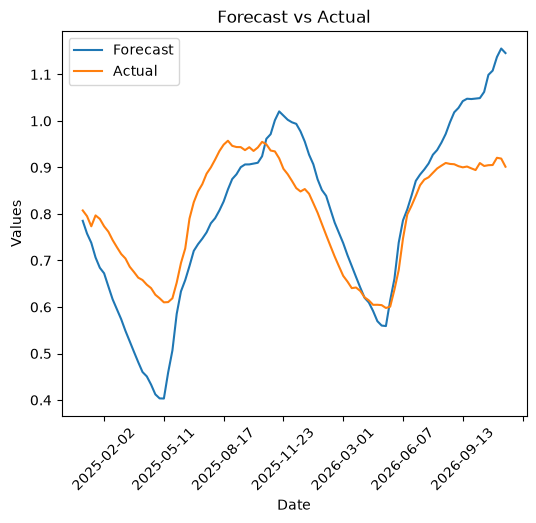

In [138]:
X = df_mag.set_index(pd.to_datetime(df_mag["dato_Id"]))["fyllingsgrad"].dropna().sort_index()

results = pred_coming_months_fillings(X)

# Plot results
import matplotlib.dates as mdates

plt.figure(figsize=(6, 5))

plt.plot(results["date"], results["forecast"], label="Forecast")
plt.plot(results["date"], results["real"], label="Actual")

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))

plt.xlabel("Date")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.title("Forecast vs Actual")
plt.legend()

plt.show()

### Testing the model

In [139]:
def test_sarimax_settings(
    X,
    horizon=12,
    histories=(104, 260, 520),
    orders=(
        (1, 0, 0), (2, 0, 0), (3, 0, 0),
        (0, 0, 1), (0, 0, 2),
        (1, 0, 1), (2, 0, 1),
        (1, 1, 0), (1, 1, 1),
    ),
    seasonal_orders=((0, 0, 0), (1, 0, 0), (0, 0, 1)),
    m=52,
):
    """Compare a small SARIMAX grid on the same final holdout period."""
    X = X.dropna().sort_index()
    if len(X) < max(histories) + horizon:
        raise ValueError(
            f"Need at least {max(histories) + horizon} weekly observations; "
            f"got {len(X)}."
        )

    rows = []
    for history, (p, d, q), (sp, sd, sq) in itertools.product(
        histories, orders, seasonal_orders
    ):
        prediction = pred_coming_months_fillings(
            X, horizon, history, p, d, q, m, sp, sd, sq
        )
        error = prediction["real"] - prediction["forecast"]
        total_variation = ((prediction["real"] - prediction["real"].mean()) ** 2).sum()
        r2 = (
            1 - (error ** 2).sum() / total_variation
            if total_variation > 0 else float("nan")
        )
        rows.append(
            {
                "history_weeks": history,
                "p": p,
                "d": d,
                "q": q,
                "m": m,
                "sp": sp,
                "sd": sd,
                "sq": sq,
                "MAE": error.abs().mean(),
                "R2": r2,
            }
        )

    return pd.DataFrame(rows).sort_values(
        ["MAE", "R2"], ascending=[True, False]
    ).reset_index(drop=True)

test_results = test_sarimax_settings(X, horizon=12)
display(test_results.round(4))

# Use the best row for the Streamlit defaults.
best_settings = test_results.iloc[0].to_dict()
best_settings

MAE: 0.23569
MAE: 0.253051
MAE: 0.2393
MAE: 0.25561
MAE: 0.235418
MAE: 0.252947
MAE: 0.239611
MAE: 0.254316
MAE: 0.247668
MAE: 0.261732
MAE: 0.246356
MAE: 0.258033
MAE: 0.25088
MAE: 0.263441
MAE: 0.245391
MAE: 0.252245
MAE: 0.248065
MAE: 0.263223
MAE: 0.247199
MAE: 0.261774
MAE: 0.251704
MAE: 0.264921
MAE: 0.246824
MAE: 0.256463


,history_weeks,p,d,q,m,sp,sd,sq,MAE,R2
0,104,2,0,0,52,0,0,0,0.2354,-0.0290
1,104,1,0,0,52,0,0,0,0.2357,-0.0317
2,104,1,0,1,52,0,0,0,0.2393,-0.0060
3,104,2,0,1,52,0,0,0,0.2396,-0.0162
4,260,2,0,1,52,0,0,0,0.2454,-0.0202
5,260,1,0,1,52,0,0,0,0.2464,-0.0229
6,520,2,0,1,52,0,0,0,0.2468,-0.0241
7,520,1,0,1,52,0,0,0,0.2472,-0.0228
8,260,1,0,0,52,0,0,0,0.2477,-0.0245
9,520,1,0,0,52,0,0,0,0.2481,-0.0271


{'history_weeks': 104.0,
 'p': 2.0,
 'd': 0.0,
 'q': 0.0,
 'm': 52.0,
 'sp': 0.0,
 'sd': 0.0,
 'sq': 0.0,
 'MAE': 0.23541808041891799,
 'R2': -0.02903030469509371}